# Entendimiento de los datos

## Carga de la matriz final

Se carga la matriz territorial exportada por el ETL del proyecto. La base reúne información de 1.098 sectores catastrales de Bogotá e incluye indicadores de oferta en Airbnb, valor de referencia del suelo, estrato, transporte y seguridad. Los indicadores de seguridad se calcularon a nivel de localidad y se incorporaron a los sectores correspondientes.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from google.colab import drive

ModuleNotFoundError: No module named 'google'

In [11]:
# Montar Drive y leer la matriz exportada por el ETL.
drive.mount("/content/drive")
ruta = Path("/content/drive/MyDrive/Guia 4/matriz_barrios_unificada.csv")
if not ruta.is_file():
    raise FileNotFoundError(f"Reemplaza ruta con la ruta que muestra Colab: {ruta}")

matriz_final = pd.read_csv(ruta)
print(f"Filas: {len(matriz_final):,} | Columnas: {matriz_final.shape[1]}")
display(matriz_final.drop(columns="geometry", errors="ignore").head())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Filas: 1,098 | Columnas: 14


,localidad,barrio,estrato_predominante,area_km2,v_ref_2015,v_ref_2026,cagr_15_26,delitos_2018,delitos_2026,cagr_delitos_18_26,num_estaciones_transmilenio,num_listings_airbnb,densidad_airbnb_km2
0,USME,EL BOSQUE,1.0,0.055879,290000.0,660000.0,0.077625,6852.0,5761.0,-0.021445,0,0.0,0.000000
1,SUBA,BILBAO,2.0,0.295314,750000.0,2050000.0,0.095719,22038.0,17403.0,-0.029084,0,0.0,0.000000
2,KENNEDY,CIUDAD KENNEDY CENTRAL,3.0,0.476473,1000000.0,2640000.0,0.092264,24725.0,17188.0,-0.044433,0,7.0,14.691286
3,CHAPINERO,CONCEPCION NORTE,3.0,0.140259,1400000.0,4380000.0,0.109255,13995.0,9476.0,-0.047573,1,0.0,0.000000
4,PUENTE ARANDA,COLON,3.0,0.285947,1300000.0,3170000.0,0.084407,9632.0,9405.0,-0.002977,0,16.0,55.954334


## 2. Completitud

El conteo y el porcentaje de nulos se calculan para todas las columnas después de la limpieza.

In [12]:
nulos = matriz_final.isna()
display(pd.DataFrame({
    "Cantidad de nulos": nulos.sum(),
    "Porcentaje de nulos": nulos.mean().mul(100).round(2),
}).rename_axis("Columna"))

,Cantidad de nulos,Porcentaje de nulos
Columna,,
localidad,0,0.0
barrio,0,0.0
estrato_predominante,0,0.0
area_km2,0,0.0
v_ref_2015,0,0.0
v_ref_2026,0,0.0
cagr_15_26,0,0.0
delitos_2018,0,0.0
delitos_2026,0,0.0


## 3. Unicidad

Se revisa que cada combinación de localidad y barrio aparezca una sola vez. Si hay duplicados, se muestran todas las filas involucradas para examinarlas.

In [13]:
llave = ["localidad", "barrio"]
# keep=False marca todas las apariciones de cada llave repetida.
duplicados = matriz_final.loc[matriz_final.duplicated(llave, keep=False)]
print(f"Combinaciones únicas: {len(matriz_final[llave].drop_duplicates()):,}")
print(f"Filas involucradas en duplicados: {len(duplicados):,}")
if not duplicados.empty:
    display(duplicados.drop(columns="geometry", errors="ignore"))

Combinaciones únicas: 1,098
Filas involucradas en duplicados: 0


## 4. Estadísticas descriptivas

La mediana y los cuartiles describen el centro y la dispersión de cada indicador. El P95 y el máximo señalan la cola alta. Se incluyen ceros registrados y la mediana de densidad entre sectores con anuncios para diferenciar presencia e intensidad de oferta.

In [15]:
pesos = "Valor de referencia 2026 (COP/m²)"
cagr = "CAGR inmobiliario (% anual)"
densidad = "Airbnb (anuncios/km²)"
variables = pd.DataFrame({
    "Anuncios Airbnb": matriz_final.num_listings_airbnb,
    densidad: matriz_final.densidad_airbnb_km2,
    pesos: matriz_final.v_ref_2026,
    cagr: matriz_final.cagr_15_26 * 100,
    "Estaciones de TransMilenio": matriz_final.num_estaciones_transmilenio,
})

# Mantener valores numéricos y aplicar formato solo al mostrar la tabla.
resumen = variables.describe(percentiles=[.25, .50, .75, .95]).T
resumen = resumen[["min", "25%", "50%", "75%", "95%", "max"]]
resumen.columns = ["Mínimo", "P25", "Mediana", "P75", "P95", "Máximo"]
columnas_estadisticas = resumen.columns.tolist()
resumen["Sectores con cero"] = variables.eq(0).sum()
resumen["% con cero"] = variables.eq(0).sum().div(variables.notna().sum()).mul(100)

def formato_cop(valor):
    return f"${valor:,.0f}".replace(",", ".")

display(resumen.style.format(precision=2, decimal=",", thousands=".")
    .format(formato_cop, subset=pd.IndexSlice[[pesos], columnas_estadisticas])
    .format("{:,.0f}", subset=["Sectores con cero"], thousands=".")
    .format("{:.2f} %", subset=["% con cero"], decimal=","))
con_airbnb = matriz_final.num_listings_airbnb.gt(0)
print(f"Sectores con anuncios: {con_airbnb.sum()} de {len(matriz_final)}")
print(f"Mediana de densidad entre sectores con anuncios: {variables.loc[con_airbnb, densidad].median():.2f} anuncios/km²")

,Mínimo,P25,Mediana,P75,P95,Máximo,Sectores con cero,% con cero
Anuncios Airbnb,"0,00","0,00","0,00","5,00","60,15","883,00",598,"54,46 %"
Airbnb (anuncios/km²),"0,00","0,00","0,00","14,05","154,73","1.277,36",598,"54,46 %"
Valor de referencia 2026 (COP/m²),$12.600,$940.000,$2.440.000,$3.438.000,$5.107.650,$17.785.000,0,"0,00 %"
CAGR inmobiliario (% anual),"-29,23","7,63","9,76","12,32","24,22","56,02",0,"0,00 %"
Estaciones de TransMilenio,"0,00","0,00","0,00","0,00","1,00","3,00",987,"89,89 %"


Sectores con anuncios: 500 de 1098
Mediana de densidad entre sectores con anuncios: 16.26 anuncios/km²


De 1.098 sectores, 500 (45,54 %) registran al menos un anuncio y 598 (54,46 %) tienen cero anuncios registrados. La mediana de densidad es cero para toda la matriz y 16,26 anuncios/km² entre los sectores con oferta observada. La primera cifra describe la cobertura y la segunda, la intensidad donde hay anuncios.

El valor de referencia de 2026 tiene una mediana de $2.440.000 COP/m². El CAGR mediano es 9,76 % anual. En 987 sectores (89,89 %) se registran cero estaciones de trasmilenio dentro del polígono.

## 5. Distribuciones

El gráfico de barras muestra la proporción de sectores con y sin anuncios. El histograma de densidad usa los sectores con anuncios y una escala logarítmica para hacer visible la cola alta. Los histogramas del valor del suelo y del CAGR muestran la distribución completa.

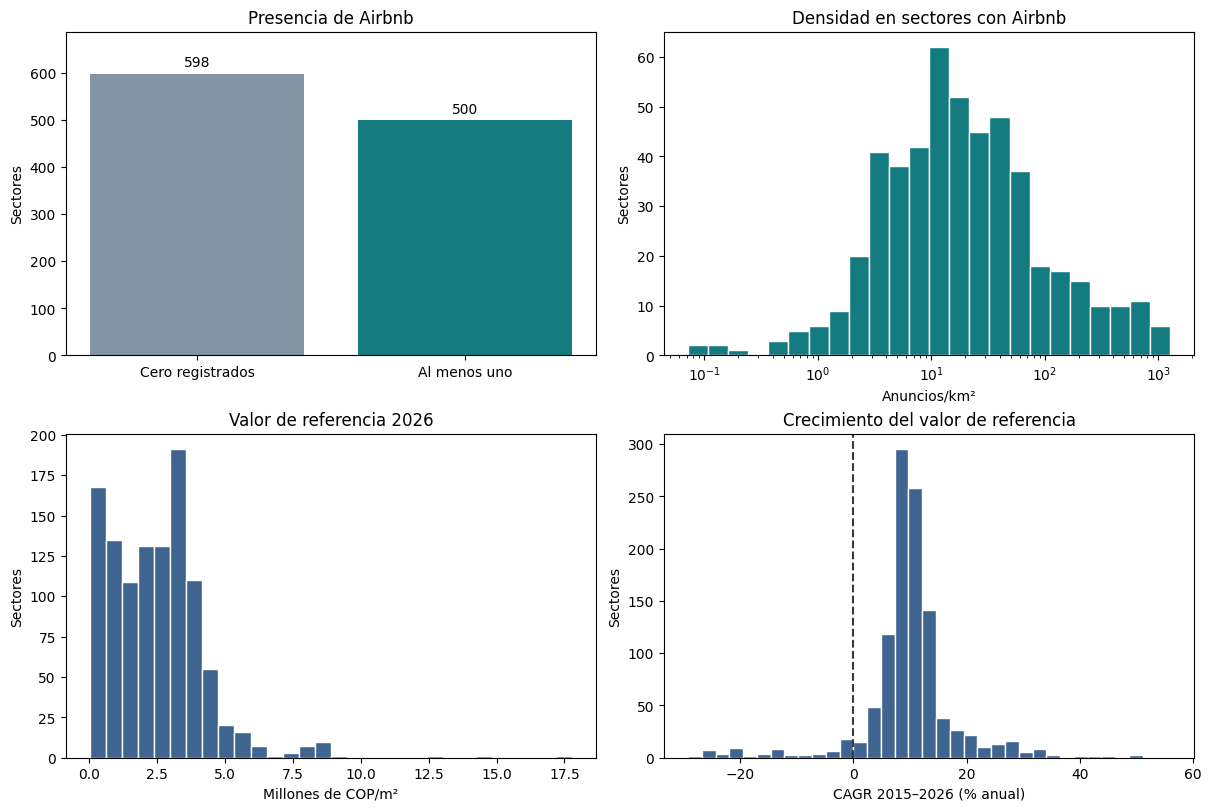

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True)
presencia = con_airbnb.value_counts().reindex([False, True], fill_value=0)
barras = axes[0, 0].bar(["Cero registrados", "Al menos uno"], presencia, color=["#8294a5", "#147c80"])
axes[0, 0].bar_label(barras, padding=3)
axes[0, 0].set_ylim(0, max(presencia.max(), 1) * 1.15)
axes[0, 0].set(title="Presencia de Airbnb", ylabel="Sectores")

# Los intervalos logarítmicos permiten mostrar densidades muy distintas en el mismo eje.
positivas = variables.loc[con_airbnb & variables[densidad].gt(0), densidad]
if positivas.nunique() > 1:
    intervalos = np.geomspace(positivas.min(), positivas.max(), 25)
    axes[0, 1].hist(positivas, bins=intervalos, color="#147c80", edgecolor="white")
    axes[0, 1].set_xscale("log")
else:
    axes[0, 1].hist(positivas, color="#147c80")
axes[0, 1].set(title="Densidad en sectores con Airbnb", xlabel="Anuncios/km²", ylabel="Sectores")

axes[1, 0].hist(variables[pesos] / 1_000_000, bins=30, color="#3f6490", edgecolor="white")
axes[1, 0].set(title="Valor de referencia 2026", xlabel="Millones de COP/m²", ylabel="Sectores")
axes[1, 1].hist(variables[cagr], bins=35, color="#3f6490", edgecolor="white")
axes[1, 1].axvline(0, color="#343a40", linestyle="--")
axes[1, 1].set(title="Crecimiento del valor de referencia", xlabel="CAGR 2015–2026 (% anual)", ylabel="Sectores")
plt.show()

1. Como se contrasta anteriormente la de los 1.098 sectores analizados, 500 (45,54 %) registran al menos un anuncio y 598 (54,46 %) tienen cero anuncios en la matriz.

2. Densidad de Airbnb en sectores con anuncios. Entre los 500 sectores con oferta registrada, la mediana es de 16,26 anuncios por km². La distribución presenta una cola hacia densidades altas, con un máximo de 1.277,36 anuncios por km².

3. Valor de referencia del suelo en 2026. La mediana es de 2.440.000 COP/m² y la mitad central de los sectores se ubica entre 940.000 y 3.438.000 COP/m². El máximo alcanza 17.785.000 COP/m², por encima del percentil 95 de 5.107.650 COP/m².

4. Crecimiento anual compuesto del valor de referencia, 2015–2026. El crecimiento mediano fue de 9,76 % anual y la mitad central de los sectores se ubicó entre 7,63 % y 12,32 % anual. La línea vertical en cero separa los sectores donde cayó el valor de referencia de aquellos donde aumentó. Los extremos van de −29,23 % a 56,02 % anual.

## 6. Revisión de extremos

La densidad se contrasta con el conteo y el área. El CAGR se contrasta con el valor inicial y final. Las tablas permiten elegir casos para verificar en los insumos del ETL. El CSV final carece de banderas de imputación por sector.

In [18]:
# Seleccionar extremos para inspección, manteniendo todas las filas para el análisis.
campos_airbnb = llave + ["num_listings_airbnb", "area_km2", "densidad_airbnb_km2"]
campos_suelo = llave + ["v_ref_2015", "v_ref_2026", "cagr_15_26"]
display(matriz_final.nlargest(5, "densidad_airbnb_km2")[campos_airbnb].style.format(
    {"num_listings_airbnb": "{:.0f}", "area_km2": "{:.4f}", "densidad_airbnb_km2": "{:,.2f}"},
    decimal=",", thousands="."))
extremos = pd.concat([
    matriz_final.nsmallest(5, "cagr_15_26")[campos_suelo].assign(grupo="CAGR más bajo"),
    matriz_final.nlargest(5, "cagr_15_26")[campos_suelo].assign(grupo="CAGR más alto"),
], ignore_index=True)
display(extremos[["grupo"] + campos_suelo].style.format(
    {"v_ref_2015": formato_cop, "v_ref_2026": formato_cop, "cagr_15_26": "{:.2%}"},
    decimal=","))

,localidad,barrio,num_listings_airbnb,area_km2,densidad_airbnb_km2
1008,TEUSAQUILLO,CHAPINERO OCCIDENTAL,405,"0,3171","1.277,36"
1020,SANTA FE,VERACRUZ,438,"0,3496","1.252,71"
1063,TEUSAQUILLO,EL RECUERDO,394,"0,3353","1.175,22"
296,CHAPINERO,CHICO NORTE,883,"0,9698","910,48"
958,SANTA FE,SAMPER,188,"0,2111","890,43"


,grupo,localidad,barrio,v_ref_2015,v_ref_2026,cagr_15_26
0,CAGR más bajo,CHAPINERO,SAN ISIDRO RURAL,"$2,500,000","$55,750","-29,23%"
1,CAGR más bajo,CHAPINERO,PARAMO II,"$2,500,000","$79,900","-26,88%"
2,CAGR más bajo,SAN CRISTOBAL,TIBAQUE I,"$450,000","$16,200","-26,08%"
3,CAGR más bajo,SAN CRISTOBAL,AGUAS CLARAS,"$450,000","$16,200","-26,08%"
4,CAGR más bajo,KENNEDY,GALAN RURAL,"$1,000,000","$38,100","-25,70%"
5,CAGR más alto,USAQUEN,ESCUELA DE CABALLERIA I,"$25,000","$3,332,790","56,02%"
6,CAGR más alto,CIUDAD BOLIVAR,ESPINO,"$9,000","$790,000","50,20%"
7,CAGR más alto,CIUDAD BOLIVAR,ESPINO I,"$9,000","$790,000","50,20%"
8,CAGR más alto,SANTA FE,SANTA INES,"$220,000","$17,785,000","49,08%"
9,CAGR más alto,SAN CRISTOBAL,TIBAQUE III,"$6,000","$389,540","46,14%"


Chapinero Occidental, en Teusaquillo, encabeza la densidad con 1.277,36 anuncios/km², producto de 405 anuncios en 0,3171 km². Chicó Norte registra 883 anuncios en 0,9698 km² y queda en 910,48 anuncios/km². Los dos casos muestran por qué el área cambia el orden de los sectores según el indicador usado.

Escuela de Caballería I tiene el CAGR máximo (56,02 %), con un valor inicial de 25.000 COP/m². San Isidro Rural tiene el mínimo (−29,23 %), al pasar de $2.500.000 a 55.750 COP/m². Una base baja puede amplificar la tasa de crecimiento.

## 7. Comparación por localidad

Se compara el porcentaje de sectores con Airbnb en cada localidad. Se muestran los denominadores y el conteo total de anuncios. La densidad agregada se obtiene dividiendo los anuncios de la localidad por el área de sus sectores incluidos en la matriz.

,sectores,sectores_con_airbnb,anuncios,area_incluida_km2,mediana_cagr,pct_sectores_con_airbnb,anuncios_km2_area_incluida
localidad,,,,,,,
BARRIOS UNIDOS,24,21,341.0,7.06,0.09,87.50,48.29
LOS MARTIRES,8,7,45.0,1.65,0.10,87.50,27.24
TEUSAQUILLO,30,24,2046.0,10.94,0.10,80.00,186.97
ENGATIVA,85,64,845.0,36.05,0.08,75.29,23.44
PUENTE ARANDA,56,39,230.0,22.73,0.10,69.64,10.12
SUBA,102,68,622.0,72.79,0.10,66.67,8.54
USAQUEN,87,58,3338.0,67.48,0.07,66.67,49.46
CHAPINERO,55,36,4000.0,34.76,0.07,65.45,115.07
FONTIBON,54,35,828.0,37.84,0.08,64.81,21.88


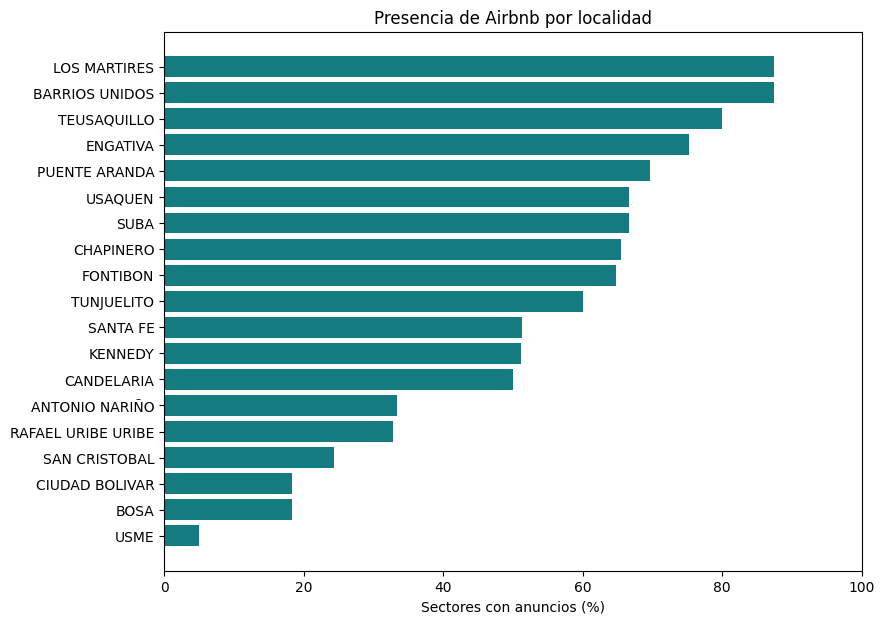

In [20]:
# Agregar conteos y áreas antes de calcular porcentajes y densidad territorial.
territorio = matriz_final.assign(con_airbnb=con_airbnb).groupby("localidad").agg(
    sectores=("barrio", "size"),
    sectores_con_airbnb=("con_airbnb", "sum"),
    anuncios=("num_listings_airbnb", "sum"),
    area_incluida_km2=("area_km2", "sum"),
    mediana_cagr=("cagr_15_26", "median"),
)
territorio["pct_sectores_con_airbnb"] = territorio.sectores_con_airbnb / territorio.sectores * 100
territorio["anuncios_km2_area_incluida"] = territorio.anuncios / territorio.area_incluida_km2
display(territorio.sort_values("pct_sectores_con_airbnb", ascending=False).round(2))

orden = territorio.sort_values("pct_sectores_con_airbnb")
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(orden.index, orden.pct_sectores_con_airbnb, color="#147c80")
ax.set(xlabel="Sectores con anuncios (%)", title="Presencia de Airbnb por localidad", xlim=(0, 100))
plt.show()

Barrios Unidos y Los Mártires tienen la mayor proporción de sectores con anuncios (87,50 % en ambos casos), con denominadores distintos (21 de 24 y 7 de 8). Chapinero registra el mayor volumen, con 4.000 anuncios en 55 sectores incluidos, de los cuales 36 tienen oferta registrada. La Candelaria muestra la mayor densidad agregada (669,46 anuncios/km²) sobre apenas dos sectores incluidos. Estos resultados distinguen extensión, volumen e intensidad y deben leerse sobre el área cubierta por la matriz.

## 8. Coincidencia de densidad alta y crecimiento alto

Se usan los percentiles 75 de toda la matriz como cortes exploratorios. Se exige densidad positiva para que un cero quede fuera del grupo de oferta alta. La dispersión y la tabla identifican sectores donde coinciden ambos indicadores. Los cortes sirven para explorar candidatos a revisión.

P75 de densidad: 14.05 anuncios/km²
P75 de CAGR: 12.32%
Sectores con ambos indicadores altos: 27 de 1098


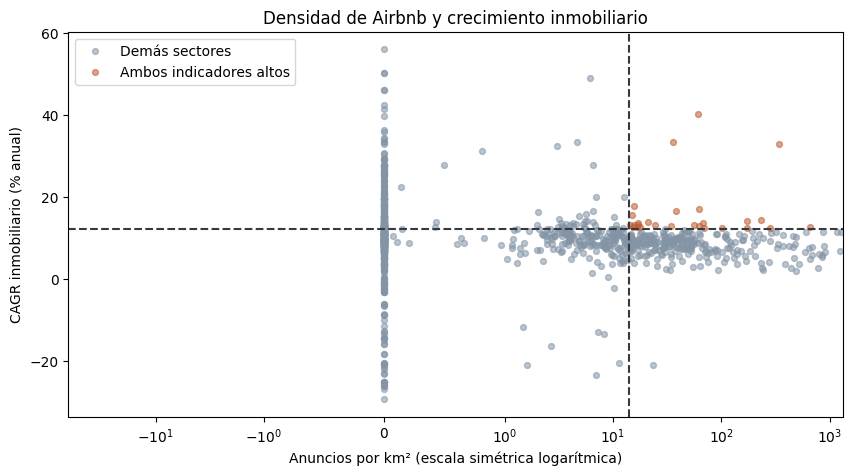

,Sectores con ambos indicadores altos
localidad,
SUBA,6
SANTA FE,5
FONTIBON,2
CHAPINERO,2
BARRIOS UNIDOS,2
USAQUEN,2
KENNEDY,2
CIUDAD BOLIVAR,1
RAFAEL URIBE URIBE,1


,localidad,barrio,densidad_airbnb_km2,cagr_15_26
337,SANTA FE,LAS NIEVES,661.020169,0.127257
814,CHAPINERO,MARIA CRISTINA,344.083118,0.330117
819,TEUSAQUILLO,SANTA TERESITA,282.481184,0.124527
137,SANTA FE,LA ALAMEDA,231.450534,0.143095
539,BARRIOS UNIDOS,ALCAZARES,174.219900,0.124909
774,SANTA FE,SAGRADO CORAZON,172.750430,0.141525
196,BARRIOS UNIDOS,ALCAZARES NORTE,102.422578,0.124909
743,SANTA FE,LAS AGUAS,69.648087,0.124410
410,LOS MARTIRES,SAMPER MENDOZA,67.185548,0.136742
218,CHAPINERO,EL REFUGIO I,62.184005,0.170987


In [22]:
umbral_airbnb = matriz_final.densidad_airbnb_km2.quantile(.75)
umbral_cagr = matriz_final.cagr_15_26.quantile(.75)
prioridad = (matriz_final.densidad_airbnb_km2.gt(0)
             & matriz_final.densidad_airbnb_km2.ge(umbral_airbnb)
             & matriz_final.cagr_15_26.ge(umbral_cagr))
print(f"P75 de densidad: {umbral_airbnb:.2f} anuncios/km²")
print(f"P75 de CAGR: {umbral_cagr:.2%}")
print(f"Sectores con ambos indicadores altos: {prioridad.sum()} de {len(matriz_final)}")

# symlog conserva el cero y comprime los valores altos del eje horizontal.
fig, ax = plt.subplots(figsize=(10, 5))
for mascara, etiqueta, color in [(~prioridad, "Demás sectores", "#8294a5"),
                                  (prioridad, "Ambos indicadores altos", "#bd5c31")]:
    ax.scatter(matriz_final.loc[mascara, "densidad_airbnb_km2"],
               matriz_final.loc[mascara, "cagr_15_26"] * 100,
               alpha=.55, s=18, color=color, label=etiqueta)
ax.axvline(umbral_airbnb, color="#343a40", linestyle="--")
ax.axhline(umbral_cagr * 100, color="#343a40", linestyle="--")
ax.set_xscale("symlog", linthresh=1)
ax.set(xlabel="Anuncios por km² (escala simétrica logarítmica)",
       ylabel="CAGR inmobiliario (% anual)", title="Densidad de Airbnb y crecimiento inmobiliario")
ax.legend()
plt.show()

seleccion = matriz_final.loc[prioridad, llave + ["densidad_airbnb_km2", "cagr_15_26"]]
display(seleccion.groupby("localidad").size().sort_values(ascending=False).rename("Sectores con ambos indicadores altos"))
display(seleccion.sort_values("densidad_airbnb_km2", ascending=False).head(15))


Con cortes de 14,05 anuncios/km² y 12,32 % anual de CAGR, 27 de 1.098 sectores (2,46 %) cumplen ambas condiciones. Suba aporta seis y Santa Fe cinco. Juntas reúnen 11 de los 27 seleccionados (40,74 %). Las Nieves tiene la mayor densidad dentro del segmento (661,02 anuncios/km² y 12,73 % de CAGR). María Cristina combina 344,08 anuncios/km² con un CAGR de 33,01 %.

La coincidencia permite acotar una primera lista de sectores para revisión. Los percentiles son cortes exploratorios relativos a esta matriz y la coincidencia por sí sola no permite atribuir el crecimiento del suelo a Airbnb.

## 9. Mapa de los sectores seleccionados

El mapa muestra la ubicación de los sectores que superan ambos cortes. Se toma la geometría del CSV y se omiten las geometrías vacías o inválidas del mapa, con un conteo explícito.

Geometrías omitidas: 4


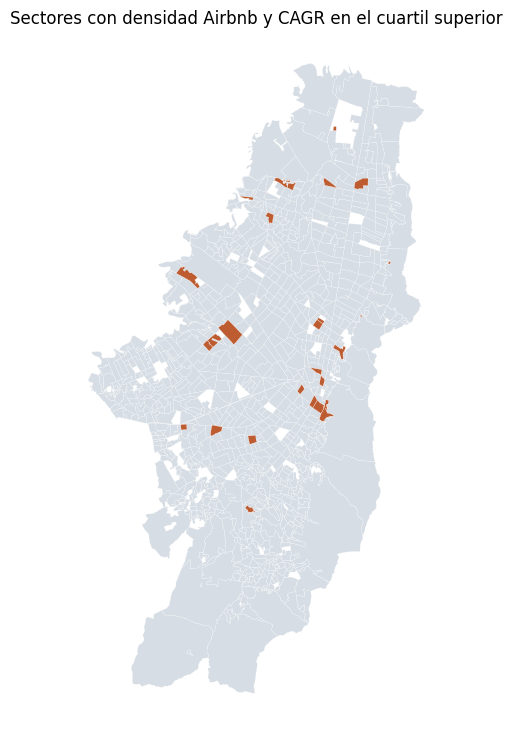

In [32]:
import geopandas as gpd
from shapely import from_wkt

# Convertir la columna WKT a geometrías. Para visualizar no se requiere calcular áreas nuevamente.
geometrias = gpd.GeoSeries(from_wkt(matriz_final.geometry.to_numpy(), on_invalid="ignore"), index=matriz_final.index)
dibujables = geometrias.notna() & geometrias.is_valid & ~geometrias.is_empty
print(f"Geometrías omitidas: {(~dibujables).sum()}")
mapa = gpd.GeoDataFrame(matriz_final[llave].assign(ambos_altos=prioridad), geometry=geometrias)
if dibujables.any():
    fig, ax = plt.subplots(figsize=(8, 9))
    mapa.loc[dibujables].plot(ax=ax, color="#d6dde4", edgecolor="white", linewidth=.15)
    destacados = mapa.loc[dibujables & prioridad]
    if not destacados.empty:
        destacados.plot(ax=ax, color="#bd5c31", edgecolor="white", linewidth=.2)
    ax.set_title("Sectores con densidad Airbnb y CAGR en el cuartil superior")
    ax.set_axis_off()
    plt.show()

## 10. Técnicas aplicadas, hallazgos y aporte a la decisión

Esta tabla se genera al final, con las salidas de las celdas anteriores. Para las técnicas del ETL se explica qué problema resolvieron, cómo se aplicaron y por qué importan. Las cifras de la auditoría histórica se identifican como resultados del ETL original.

In [33]:
# Recuperar los resultados calculados con el CSV que se cargó en esta ejecución.
n = len(matriz_final)
con_oferta = int(con_airbnb.sum())
mediana_positiva = variables.loc[con_airbnb, densidad].median()
n_prioridad = int(prioridad.sum())
por_localidad = matriz_final.loc[prioridad].groupby("localidad").size().sort_values(ascending=False)
principales = ", ".join(f"{nombre} ({cantidad})" for nombre, cantidad in por_localidad.head(3).items())

# Cada fila vincula la lógica del método con un resultado y su uso en el proyecto.
tecnicas = [
    ("Filtración", "El ETL excluyó sectores cuyos valores inicial o final del suelo seguían faltantes o en cero. En la exploración se usa toda la matriz para medir presencia y se seleccionan sectores con anuncios para medir intensidad.",
     f"{con_oferta} de {n} sectores tienen anuncios. La mediana de densidad en ese subconjunto es {mediana_positiva:.2f} anuncios/km². Así se puede distinguir alcance territorial de intensidad local.", "ETL y secciones 4–6"),
    ("Imputación", "Los ceros inmobiliarios se trataron como faltantes. Para 2015 se usó la mediana por localidad. Para 2026 se usó el historial del sector, que al estar en el extremo puede arrastrar el último valor disponible, y la mediana por localidad como respaldo. El estrato faltante se rellenó con la moda de la localidad.",
     f"En la tabla inmobiliaria del ETL original, 76 sectores tenían anomalías en los extremos y 5 quedaron sin valor base tras el relleno. El CSV cargado tiene {int(nulos.sum().sum())} nulos en total. La imputación preserva cobertura, pero puede cambiar el CAGR y la selección por percentiles. El CSV carece de marcas de imputación por sector.", "Auditoría del ETL y secciones 2 y 6"),
    ("Reducción de dimensiones", "Se aplaza para conservar indicadores que se puedan interpretar directamente por sector. La densidad y el CAGR conservan sus unidades para interpretar los cortes.",
     "La decisión mantiene interpretables los cortes y permite explicar por qué un sector se seleccionó para revisión.", "Secciones 4, 6 y 8"),
    ("Extracción y transformación de variables", "El ETL calculó densidad dividiendo anuncios por área en km² y CAGR como (valor 2026 / valor 2015) elevado a 1/11, menos 1. El histograma usa escala logarítmica para visualizar la cola de densidades.",
     f"El P95 de densidad es {variables[densidad].quantile(.95):.2f} anuncios/km² y la mediana de CAGR es {variables[cagr].median():.2f} % anual. La densidad facilita la comparación entre sectores de distinto tamaño y el CAGR resume el cambio anual equivalente del valor de referencia.", "ETL y secciones 4–6"),
    ("Estadísticas básicas", "Se resumen el centro, los cuartiles, los ceros y la cola alta. Los gráficos ayudan a interpretar la dispersión y las observaciones extremas.",
     f"{n - con_oferta} sectores ({(n-con_oferta)/n:.2%}) tienen cero anuncios registrados. La mediana del valor de referencia de 2026 es {formato_cop(variables[pesos].median())} COP/m².", "Secciones 4–6"),
    ("Adición de información", "El ETL usa un cruce espacial para vincular sectores y localidades. Integra el estrato predominante de las manzanas, el conteo de estaciones dentro del sector y los indicadores de seguridad agregados por localidad. La geometría permite ubicar los sectores en el mapa.",
     f"{int(matriz_final.num_estaciones_transmilenio.eq(0).sum())} sectores registran cero estaciones dentro de sus límites. El indicador describe presencia interna. La seguridad aporta contexto común a los sectores de una misma localidad.", "ETL y secciones 4, 7 y 9"),
    ("Segmentación", "Se aplican los P75 de densidad y CAGR sobre toda la matriz, con densidad positiva, para localizar coincidencias de ambos indicadores.",
     f"{n_prioridad} de {n} sectores cumplen ambos cortes. " + (f"Mayores conteos por localidad: {principales}." if n_prioridad else "La regla no seleccionó sectores con estos datos."), "Secciones 7–9"),
]
tabla_tecnicas = pd.DataFrame(tecnicas, columns=[
    "Técnica", "Uso, lógica y justificación", "Hallazgo o aporte al proyecto", "Soporte"
])
display(tabla_tecnicas.style.hide(axis="index").set_properties(**{
    "text-align": "left", "vertical-align": "top", "white-space": "normal"
}))


Técnica,"Uso, lógica y justificación",Hallazgo o aporte al proyecto,Soporte
Filtración,El ETL excluyó sectores cuyos valores inicial o final del suelo seguían faltantes o en cero. En la exploración se usa toda la matriz para medir presencia y se seleccionan sectores con anuncios para medir intensidad.,500 de 1098 sectores tienen anuncios. La mediana de densidad en ese subconjunto es 16.26 anuncios/km². Así se puede distinguir alcance territorial de intensidad local.,ETL y secciones 4–6
Imputación,"Los ceros inmobiliarios se trataron como faltantes. Para 2015 se usó la mediana por localidad. Para 2026 se usó el historial del sector, que al estar en el extremo puede arrastrar el último valor disponible, y la mediana por localidad como respaldo. El estrato faltante se rellenó con la moda de la localidad.","En la tabla inmobiliaria del ETL original, 76 sectores tenían anomalías en los extremos y 5 quedaron sin valor base tras el relleno. El CSV cargado tiene 0 nulos en total. La imputación preserva cobertura, pero puede cambiar el CAGR y la selección por percentiles. El CSV carece de marcas de imputación por sector.",Auditoría del ETL y secciones 2 y 6
Reducción de dimensiones,Se aplaza para conservar indicadores que se puedan interpretar directamente por sector. La densidad y el CAGR conservan sus unidades para interpretar los cortes.,La decisión mantiene interpretables los cortes y permite explicar por qué un sector se seleccionó para revisión.,"Secciones 4, 6 y 8"
Extracción y transformación de variables,"El ETL calculó densidad dividiendo anuncios por área en km² y CAGR como (valor 2026 / valor 2015) elevado a 1/11, menos 1. El histograma usa escala logarítmica para visualizar la cola de densidades.",El P95 de densidad es 154.73 anuncios/km² y la mediana de CAGR es 9.76 % anual. La densidad facilita la comparación entre sectores de distinto tamaño y el CAGR resume el cambio anual equivalente del valor de referencia.,ETL y secciones 4–6
Estadísticas básicas,"Se resumen el centro, los cuartiles, los ceros y la cola alta. Los gráficos ayudan a interpretar la dispersión y las observaciones extremas.",598 sectores (54.46%) tienen cero anuncios registrados. La mediana del valor de referencia de 2026 es $2.440.000 COP/m².,Secciones 4–6
Adición de información,"El ETL usa un cruce espacial para vincular sectores y localidades. Integra el estrato predominante de las manzanas, el conteo de estaciones dentro del sector y los indicadores de seguridad agregados por localidad. La geometría permite ubicar los sectores en el mapa.",987 sectores registran cero estaciones dentro de sus límites. El indicador describe presencia interna. La seguridad aporta contexto común a los sectores de una misma localidad.,"ETL y secciones 4, 7 y 9"
Segmentación,"Se aplican los P75 de densidad y CAGR sobre toda la matriz, con densidad positiva, para localizar coincidencias de ambos indicadores.","27 de 1098 sectores cumplen ambos cortes. Mayores conteos por localidad: SUBA (6), SANTA FE (5), FONTIBON (2).",Secciones 7–9
